In [9]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/deaary13/head-motion/README.dataset.txt
/kaggle/input/datasets/deaary13/head-motion/README.roboflow.txt
/kaggle/input/datasets/deaary13/head-motion/data.yaml
/kaggle/input/datasets/deaary13/head-motion/valid/labels/Terang_Frame_1722_png.rf.9294aebdb88bb75a304641fed15f7228.txt
/kaggle/input/datasets/deaary13/head-motion/valid/labels/Gelap_Frame_352_png.rf.d53c5391c7ceb698c825b713d581cef1.txt
/kaggle/input/datasets/deaary13/head-motion/valid/labels/Gelap_Frame_986_png.rf.ed5f7bb04dcb86a458ec8488c1ee2934.txt
/kaggle/input/datasets/deaary13/head-motion/valid/labels/Terang_Frame_113_png.rf.d5232701dbd408dee5adb139a6249f80.txt
/kaggle/input/datasets/deaary13/head-motion/valid/labels/Gelap_Frame_1106_png.rf.78a44783f43129e10ef315017c0a3329.txt
/kaggle/input/datasets/deaary13/head-motion/valid/labels/Gelap_Frame_120_png.rf.d257ecd44bdb75f480895e1f7fa0ee6f.txt
/kaggle/input/datasets/deaary13/head-motion/valid/labels/Gelap_Frame_593_png.rf.c14bda1d612e1f572a79fbe969b7b375.

In [10]:
!pip install facenet-pytorch --no-deps

### Library

In [11]:
import copy
from collections import Counter
import os
from pathlib import Path
import time
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, models, transforms
import timm
import yaml
import numpy as np
from PIL import Image

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Menggunakan device: {device}')

Menggunakan device: cuda


### TEMUKAN PATH DATASET

In [12]:
input_dir = Path('/kaggle/input')
dataset_path = None

for p in input_dir.rglob('datasets/deaary13/head-motion'):  # Sesuaikan nama folder RAF-DB di kaggle-mu
  if p.is_dir():
    dataset_path = p
    break

# # Fallback pencarian umum jika namanya sedikit berbeda
# if not dataset_path:
#   for p in input_dir.rglob('*raf*'):
#     if p.is_dir():
#       dataset_path = p
#       break

if dataset_path:
  DATA_DIR = dataset_path
  print(f'Berhasil menemukan dataset head-motion di: {DATA_DIR}')
else:
  raise FileNotFoundError(
      'Folder dataset head-motion tidak ditemukan! Pastikan sudah di-add ke Kaggle.'
  )

# Tentukan direktori train dan test
train_dir = DATA_DIR / '/train'
test_dir = DATA_DIR / '/test'
valid_dir = DATA_DIR / "/valid"

# Jika struktur foldernya langsung train/test di root
if not train_dir.exists():
  # Cek struktur alternatif
  subdirs = [x for x in DATA_DIR.iterdir() if x.is_dir()]
  print('Subfolder yang tersedia:', subdirs)

Berhasil menemukan dataset head-motion di: /kaggle/input/datasets/deaary13/head-motion
Subfolder yang tersedia: [PosixPath('/kaggle/input/datasets/deaary13/head-motion/valid'), PosixPath('/kaggle/input/datasets/deaary13/head-motion/test'), PosixPath('/kaggle/input/datasets/deaary13/head-motion/train')]


### Data Deskriptif

In [13]:
splits = ['train', 'valid', 'test']

descriptive_stats = {}

for split in splits:
  img_dir = DATA_DIR / split / 'images'
  lbl_dir = DATA_DIR / split / 'labels'

  if not img_dir.exists():
    print(f'[WARNING] Direktori {split} tidak ditemukan, dilewati.')
    continue

  valid_exts = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
  img_files = [f for f in os.listdir(img_dir) if f.lower().endswith(valid_exts)]

  total_images = len(img_files)
  label_counts = []
  widths = []
  heights = []
  missing_labels = 0

  for img_name in img_files:
    img_path = img_dir / img_name
    txt_name = Path(img_name).stem + '.txt'
    txt_path = lbl_dir / txt_name

    # 1. Cek ukuran gambar (Resolusi)
    try:
      with Image.open(img_path) as img:
        w, h = img.size
        widths.append(w)
        heights.append(h)
    except Exception as e:
      print(f'[ERROR] Gagal membaca gambar {img_path}: {e}')

    # 2. Cek distribusi kelas dari file label YOLO
    if txt_path.exists():
      with open(txt_path, 'r') as f:
        lines = f.readlines()
        has_class = False
        for line in lines:
          parts = line.strip().split()
          if parts:
            class_id = int(parts[0])
            label_counts.append(class_id)
            has_class = True
        if not has_class:
          missing_labels += 1  # File txt ada tapi kosong
    else:
      missing_labels += 1  # File txt tidak ada sama sekali

  # Simpan statistik per split
  descriptive_stats[split] = {
      'total_images': total_images,
      'label_counts': Counter(label_counts),
      'missing_labels': missing_labels,
      'avg_width': np.mean(widths) if widths else 0,
      'avg_height': np.mean(heights) if heights else 0,
      'min_width': np.min(widths) if widths else 0,
      'max_width': np.max(widths) if widths else 0,
      'min_height': np.min(heights) if heights else 0,
      'max_height': np.max(heights) if heights else 0,
  }

# ==========================================
# MENAMPILKAN LAPORAN DESKRIPTIF
# ==========================================
print('=' * 65)
print('LAPORAN ANALISIS DESKRIPTIF DATASET HEAD-MOTION')
print('=' * 65)

for split, stats in descriptive_stats.items():
  print(f"\n📂 Split: {split.upper()}")
  print(f"   - Total Gambar        : {stats['total_images']}")
  print(f"   - File Label Hilang/Kosong: {stats['missing_labels']}")
  print(
      f"   - Rata-rata Resolusi  :"
      f" {stats['avg_width']:.1f} x {stats['avg_height']:.1f} piksel"
  )
  print(
      f"   - Rentang Lebar (W)   : {stats['min_width']} s.d."
      f" {stats['max_width']} px"
  )
  print(
      f"   - Rentang Tinggi (H)  : {stats['min_height']} s.d."
      f" {stats['max_height']} px"
  )
  print('   - Distribusi per Kelas:')
  for class_id, count in sorted(stats['label_counts'].items()):
    class_label_name = (
        class_names[class_id]
        if class_id < len(class_names)
        else f'Unknown ({class_id})'
    )
    percentage = (
        (count / stats['total_images']) * 100
        if stats['total_images'] > 0
        else 0
    )
    print(
        f'     * [{class_id}] {class_label_name}: {count} sampel'
        f' ({percentage:.2f}%)'
    )



LAPORAN ANALISIS DESKRIPTIF DATASET HEAD-MOTION

📂 Split: TRAIN
   - Total Gambar        : 4210
   - File Label Hilang/Kosong: 8
   - Rata-rata Resolusi  : 640.0 x 480.0 piksel
   - Rentang Lebar (W)   : 640 s.d. 640 px
   - Rentang Tinggi (H)  : 480 s.d. 480 px
   - Distribusi per Kelas:
     * [0] atas: 886 sampel (21.05%)
     * [1] bawah: 891 sampel (21.16%)
     * [2] depan: 830 sampel (19.71%)
     * [3] kanan: 830 sampel (19.71%)
     * [4] kiri: 765 sampel (18.17%)

📂 Split: VALID
   - Total Gambar        : 261
   - File Label Hilang/Kosong: 0
   - Rata-rata Resolusi  : 640.0 x 480.0 piksel
   - Rentang Lebar (W)   : 640 s.d. 640 px
   - Rentang Tinggi (H)  : 480 s.d. 480 px
   - Distribusi per Kelas:
     * [0] atas: 55 sampel (21.07%)
     * [1] bawah: 47 sampel (18.01%)
     * [2] depan: 61 sampel (23.37%)
     * [3] kanan: 51 sampel (19.54%)
     * [4] kiri: 47 sampel (18.01%)

📂 Split: TEST
   - Total Gambar        : 262
   - File Label Hilang/Kosong: 0
   - Rata-rata Reso

/tmp/ipykernel_49/3965073600.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=names, y=values, palette='viridis')
/tmp/ipykernel_49/3965073600.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=names, y=values, palette='viridis')
/tmp/ipykernel_49/3965073600.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=names, y=values, palette='viridis')


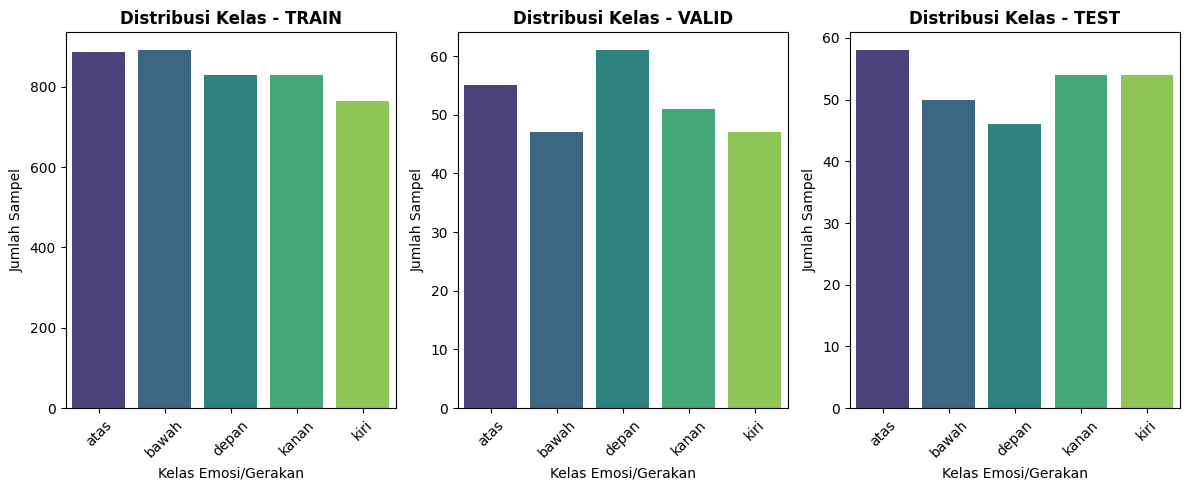

In [14]:
# ==========================================
# VISUALISASI GRAFIK DISTRIBUSI KELAS
# ==========================================
plt.figure(figsize=(12, 5))
for i, split in enumerate(splits):
  if split not in descriptive_stats:
    continue
  plt.subplot(1, len(splits), i + 1)
  counts = descriptive_stats[split]['label_counts']

  # Urutkan berdasarkan index kelas
  sorted_ids = sorted(counts.keys())
  names = [
      class_names[cid] if cid < len(class_names) else str(cid)
      for cid in sorted_ids
  ]
  values = [counts[cid] for cid in sorted_ids]

  sns.barplot(x=names, y=values, palette='viridis')
  plt.title(f'Distribusi Kelas - {split.upper()}', fontsize=12, fontweight='bold')
  plt.xlabel('Kelas Emosi/Gerakan', fontsize=10)
  plt.ylabel('Jumlah Sampel', fontsize=10)
  plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### DATA AUGMENTATION & TRANSFORM 

In [15]:
# MEMBACA FILE DATA.YML
# 1. Baca daftar nama kelas secara otomatis dari file data.yaml
yaml_path = DATA_DIR / 'data.yaml' 
if yaml_path.exists():
  with open(yaml_path, 'r') as f:
    data_info = yaml.safe_load(f)
    class_names = data_info.get('names', [])
else:
  raise FileNotFoundError(
      'File data.yaml tidak ditemukan di dalam direktori dataset!'
  )

print('Kelas emosi terdeteksi dari data.yaml:', class_names)


# 2. Buat Custom Dataset yang OTOMATIS memfilter file tanpa label (Missing Value)
class YOLOClassificationDataset(Dataset):

  def __init__(self, image_dir, label_dir, transform=None):
    self.image_dir = Path(image_dir)
    self.label_dir = Path(label_dir)
    self.transform = transform

    valid_exts = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
    raw_image_files = sorted(
        [f for f in os.listdir(self.image_dir) if f.lower().endswith(valid_exts)]
    )

    # --- FILTERING OTOMATIS: Hanya ambil gambar yang punya file .txt dan tidak kosong ---
    self.image_files = []
    for img_name in raw_image_files:
      txt_name = Path(img_name).stem + '.txt'
      txt_path = self.label_dir / txt_name

      if txt_path.exists():
        # Cek apakah file txt benar-benar ada isinya
        with open(txt_path, 'r') as f:
          line = f.readline().strip()
          if line:
            self.image_files.append(img_name)  # Masukkan karena valid

    print(
        f'[INFO] Memuat {len(self.image_files)} dari {len(raw_image_files)}'
        f' gambar valid (File kosong/hilang di-skip).'
    )

  def __len__(self):
    return len(self.image_files)

  def __getitem__(self, idx):
    img_name = self.image_files[idx]
    img_path = self.image_dir / img_name
    txt_name = Path(img_name).stem + '.txt'
    txt_path = self.label_dir / txt_name

    # Ambil class_id dari baris pertama file txt
    class_id = 0
    with open(txt_path, 'r') as f:
      line = f.readline().strip()
      parts = line.split()
      if parts:
        class_id = int(parts[0])

    # Buka gambar dan konversi ke RGB
    image = Image.open(img_path).convert('RGB')

    if self.transform:
      image = self.transform(image)

    return image, torch.tensor(class_id, dtype=torch.long)


Kelas emosi terdeteksi dari data.yaml: ['atas', 'bawah', 'depan', 'kanan', 'kiri']


In [16]:
train_dir = os.path.join(DATA_DIR, "train")
test_dir = os.path.join(DATA_DIR, "test")     # Bisa diganti valid_dir jika ingin evaluasi di valid
valid_dir = os.path.join(DATA_DIR, "valid")

# Definisikan Augmentasi Data
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(10),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),

    'valid': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    
    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

# Load Dataset menggunakan ImageFolder
image_datasets = {
    x: YOLOClassificationDataset(
        image_dir=DATA_DIR / x / 'images',
        label_dir=DATA_DIR / x / 'labels',
        transform=data_transforms[x],
    )
    for x in ['train', 'valid', 'test']
}

print("Daftar Kelas Head-Motion:", class_names)

dataloaders = {
    x: DataLoader(
        image_datasets[x], batch_size=32, shuffle=(x == 'train'), num_workers=2
    )
    for x in ['train', 'valid', 'test']
}

dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'valid', 'test']}
print('Jumlah sampel per split:', dataset_sizes)

[INFO] Memuat 4202 dari 4210 gambar valid (File kosong/hilang di-skip).
[INFO] Memuat 261 dari 261 gambar valid (File kosong/hilang di-skip).
[INFO] Memuat 262 dari 262 gambar valid (File kosong/hilang di-skip).
Daftar Kelas Head-Motion: ['atas', 'bawah', 'depan', 'kanan', 'kiri']
Jumlah sampel per split: {'train': 4202, 'valid': 261, 'test': 262}


### INISIALISASI MODEL EFFICIENTNET-B0

In [17]:
model_name = 'efficientnet_b0'
model = timm.create_model(
    model_name, pretrained=True, num_classes=len(class_names)
)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-2)
num_epochs = 15
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=num_epochs, eta_min=1e-6
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

### FUNGSI TRAINING & CHECKPOINTING

In [18]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=15):
  since = time.time()
  best_model_wts = copy.deepcopy(model.state_dict())
  best_acc = 0.0

  for epoch in range(num_epochs):
    print(f'Epoch {epoch+1}/{num_epochs}')
    print('-' * 20)

    for phase in ['train', 'valid']:
      if phase == 'train':
        model.train()
      else:
        model.eval()

      running_loss = 0.0
      running_corrects = 0

      for inputs, labels in dataloaders[phase]:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        with torch.set_grad_enabled(phase == 'train'):
          outputs = model(inputs)
          _, preds = torch.max(outputs, 1)
          loss = criterion(outputs, labels)

          if phase == 'train':
            loss.backward()
            optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)

      if phase == 'train':
        scheduler.step()

      epoch_loss = running_loss / dataset_sizes[phase]
      epoch_acc = float(running_corrects.double() / dataset_sizes[phase]) * 100

      print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.2f}%')

      # Simpan bobot terbaik berdasarkan validation accuracy
      if phase == 'valid' and epoch_acc > best_acc:
        best_acc = epoch_acc
        best_model_wts = copy.deepcopy(model.state_dict())

    print()

  time_elapsed = time.time() - since
  print(f'Training selesai dalam {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
  print(f'Akurasi Validasi Terbaik: {best_acc:.2f}%')

  model.load_state_dict(best_model_wts)
  return model


print(f'[INFO] Memulai training dengan {model_name}...')
model = train_model(model, criterion, optimizer, scheduler, num_epochs=num_epochs)

[INFO] Memulai training dengan efficientnet_b0...
Epoch 1/15
--------------------
Train Loss: 0.2300 Acc: 94.93%
Valid Loss: 0.0402 Acc: 99.62%

Epoch 2/15
--------------------
Train Loss: 0.0746 Acc: 98.45%
Valid Loss: 0.0329 Acc: 98.85%

Epoch 3/15
--------------------
Train Loss: 0.0600 Acc: 98.74%
Valid Loss: 0.0880 Acc: 98.47%

Epoch 4/15
--------------------
Train Loss: 0.0618 Acc: 98.55%
Valid Loss: 0.0383 Acc: 99.62%

Epoch 5/15
--------------------
Train Loss: 0.0500 Acc: 99.05%
Valid Loss: 0.0895 Acc: 99.23%

Epoch 6/15
--------------------
Train Loss: 0.0351 Acc: 99.14%
Valid Loss: 0.0512 Acc: 99.62%

Epoch 7/15
--------------------
Train Loss: 0.0334 Acc: 99.41%
Valid Loss: 0.0518 Acc: 99.23%

Epoch 8/15
--------------------
Train Loss: 0.0210 Acc: 99.43%
Valid Loss: 0.0614 Acc: 99.23%

Epoch 9/15
--------------------
Train Loss: 0.0187 Acc: 99.52%
Valid Loss: 0.0449 Acc: 99.62%

Epoch 10/15
--------------------
Train Loss: 0.0164 Acc: 99.55%
Valid Loss: 0.0478 Acc: 99.62%


### EVALUASI AKHIR PADA TEST SET & CONFUSION MATRIX


[INFO] Menjalankan evaluasi akhir pada Test Set...
CLASSIFICATION REPORT (TEST SET)
              precision    recall  f1-score   support

        atas     1.0000    0.9828    0.9913        58
       bawah     1.0000    0.9600    0.9796        50
       depan     0.9388    1.0000    0.9684        46
       kanan     1.0000    0.9815    0.9907        54
        kiri     0.9818    1.0000    0.9908        54

    accuracy                         0.9847       262
   macro avg     0.9841    0.9848    0.9842       262
weighted avg     0.9855    0.9847    0.9848       262



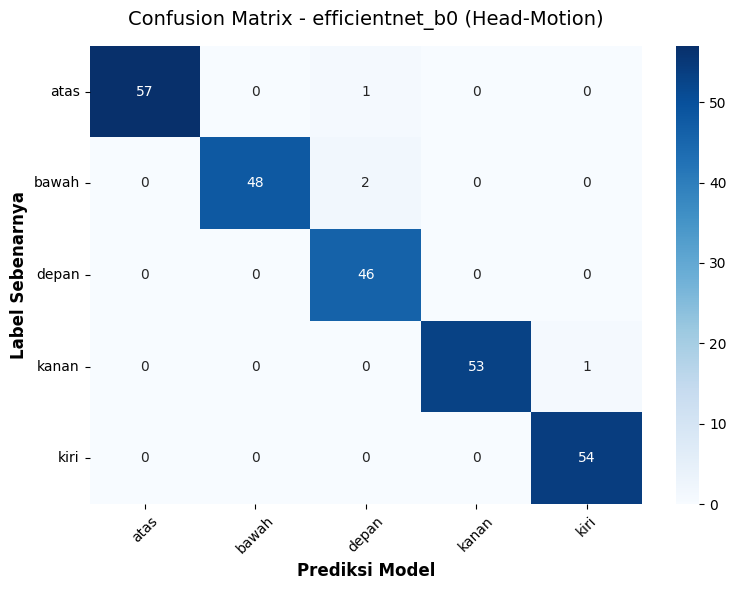

In [19]:
print('\n[INFO] Menjalankan evaluasi akhir pada Test Set...')
test_loader = DataLoader(
    image_datasets['test'], batch_size=32, shuffle=False, num_workers=2
)

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
  for inputs, labels in test_loader:
    inputs = inputs.to(device)
    labels = labels.to(device)
    outputs = model(inputs)
    _, preds = torch.max(outputs, 1)

    all_preds.extend(preds.cpu().numpy())
    all_labels.extend(labels.cpu().numpy())

print('=' * 65)
print('CLASSIFICATION REPORT (TEST SET)')
print('=' * 65)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# Visualisasi Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
)
plt.xlabel('Prediksi Model', fontsize=12, fontweight='bold')
plt.ylabel('Label Sebenarnya', fontsize=12, fontweight='bold')
plt.title(f'Confusion Matrix - {model_name} (Head-Motion)', fontsize=14, pad=15)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Menyimpan Model

In [21]:
# Simpan Model & Mapping
torch.save(model.state_dict(), f'{model_name}_headmotion.pth')
mapping_data = {'class_names': class_names}
# with open('class_mapping_headmotion.json', 'w') as f:
#   json.dump(mapping_data, f)

print(f'[INFO] Model {model_name} dan file pendukung berhasil disimpan!')

[INFO] Model efficientnet_b0 dan file pendukung berhasil disimpan!
